In [1]:
import numpy as np
import pandas as pd
import datetime as dt

In [2]:
df_MJO = pd.read_table('non_ERA5_features/rmm.74toRealtime.txt', skiprows=1, sep="\s+", usecols=(0,1,2,5))
df_MJO

,"year,","month,","day,","phase,"
0,1974,6,1,5
1,1974,6,2,5
2,1974,6,3,5
3,1974,6,4,5
4,1974,6,5,5
...,...,...,...,...
18934,2026,4,3,2
18935,2026,4,4,2
18936,2026,4,5,3
18937,2026,4,6,3


In [3]:
df_MJO = df_MJO.rename(columns={'year,':'year', 'month,':'month', 'day,':'day', 'phase,':'MJO_phase'})

In [4]:
df_MJO = df_MJO.where((df_MJO['year'] < 2025) | ((df_MJO['year'] == 2025) & (df_MJO['month'] < 3)))
df_MJO = df_MJO.dropna()
df_MJO['MJO_phase'] = df_MJO['MJO_phase'].where(df_MJO['MJO_phase'] < 10)

In [5]:
df_MJO['time'] = pd.to_datetime(df_MJO[['year', 'month', 'day']])
df_MJO = df_MJO.set_index('time')
df_MJO = df_MJO.drop(['year', 'month', 'day'], axis=1)

In [6]:
missing_data = pd.DataFrame(index=pd.date_range('1950-07-01', df_MJO.index[0]-dt.timedelta(days=1)))
df_MJO = pd.concat([missing_data, df_MJO])

In [7]:
month = df_MJO.index.month
day = df_MJO.index.day
df_MJO_week3 = df_MJO[((month == 11) & (day >= 16)) | (month == 12) | (month == 1) | ((month == 2) & (day <= 7))]
df_MJO_week4 = df_MJO[((month == 11) & (day >= 9)) | (month == 12) | (month == 1)]
df_MJO_week5 = df_MJO[((month == 11) & (day >= 2)) | (month == 12) | ((month == 1) & (day <= 24))]
df_MJO_week6 = df_MJO[((month == 10) & (day >= 26)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 17))]
df_MJO_week7 = df_MJO[((month == 10) & (day >= 19)) | (month == 11) | (month == 12) | ((month == 1) & (day <= 10))]
df_MJO_week7

,MJO_phase
1950-10-19,NaN
1950-10-20,NaN
1950-10-21,NaN
1950-10-22,NaN
1950-10-23,NaN
...,...
2025-01-06,7.0
2025-01-07,8.0
2025-01-08,8.0
2025-01-09,8.0


<Axes: >

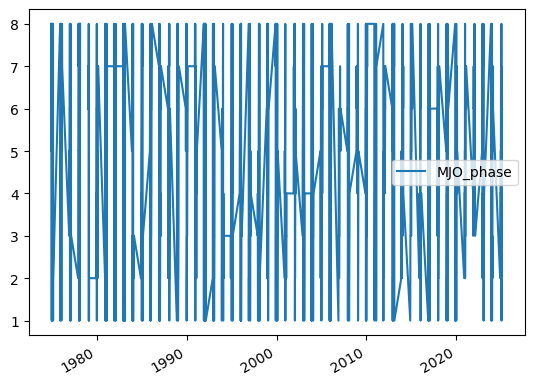

In [8]:
df_MJO_week3.plot()

In [9]:
df_MJO_week3.loc[df_MJO_week3[df_MJO_week3['MJO_phase']==1].index, 'MJO_phase'] = 9
df_MJO_week3.loc[df_MJO_week3[df_MJO_week3['MJO_phase']==2].index, 'MJO_phase'] = 10

C:\Users\lasse\AppData\Local\Temp\ipykernel_42736\1461520378.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_MJO_week3.loc[df_MJO_week3[df_MJO_week3['MJO_phase']==1].index, 'MJO_phase'] = 9
C:\Users\lasse\AppData\Local\Temp\ipykernel_42736\1461520378.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_MJO_week3.loc[df_MJO_week3[df_MJO_week3['MJO_phase']==2].index, 'MJO_phase'] = 10


<Axes: >

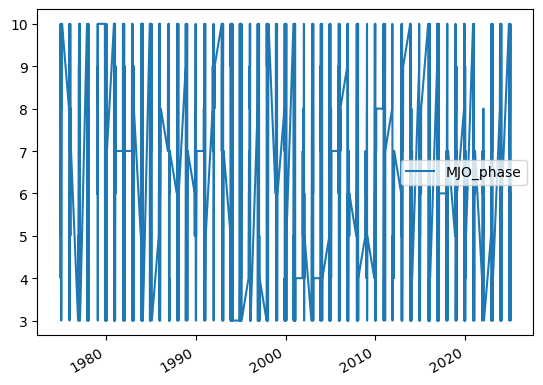

In [10]:
df_MJO_week3.plot()

In [9]:
df_MJO_week4.loc[df_MJO_week4[df_MJO_week4['MJO_phase']==1].index, 'MJO_phase'] = 9
df_MJO_week4.loc[df_MJO_week4[df_MJO_week4['MJO_phase']==2].index, 'MJO_phase'] = 10

df_MJO_week5.loc[df_MJO_week5[df_MJO_week5['MJO_phase']==1].index, 'MJO_phase'] = 9
df_MJO_week5.loc[df_MJO_week5[df_MJO_week5['MJO_phase']==2].index, 'MJO_phase'] = 10

C:\Users\lasse\AppData\Local\Temp\ipykernel_23360\550452141.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_MJO_week4.loc[df_MJO_week4[df_MJO_week4['MJO_phase']==1].index, 'MJO_phase'] = 9
C:\Users\lasse\AppData\Local\Temp\ipykernel_23360\550452141.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_MJO_week4.loc[df_MJO_week4[df_MJO_week4['MJO_phase']==2].index, 'MJO_phase'] = 10
C:\Users\lasse\AppData\Local\Temp\ipykernel_23360\550452141.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs

In [8]:
df_MJO_week6.loc[df_MJO_week6[df_MJO_week6['MJO_phase']==1].index, 'MJO_phase'] = 9
df_MJO_week6.loc[df_MJO_week6[df_MJO_week6['MJO_phase']==2].index, 'MJO_phase'] = 10

df_MJO_week7.loc[df_MJO_week7[df_MJO_week7['MJO_phase']==1].index, 'MJO_phase'] = 9
df_MJO_week7.loc[df_MJO_week7[df_MJO_week7['MJO_phase']==2].index, 'MJO_phase'] = 10

C:\Users\lasse\AppData\Local\Temp\ipykernel_26788\2023848176.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_MJO_week6.loc[df_MJO_week6[df_MJO_week6['MJO_phase']==1].index, 'MJO_phase'] = 9
C:\Users\lasse\AppData\Local\Temp\ipykernel_26788\2023848176.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_MJO_week6.loc[df_MJO_week6[df_MJO_week6['MJO_phase']==2].index, 'MJO_phase'] = 10
C:\Users\lasse\AppData\Local\Temp\ipykernel_26788\2023848176.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-d

In [11]:
df_MJO_week3.to_csv('MJO_week3.csv')

In [10]:
df_MJO_week4.to_csv('MJO_week4.csv')
df_MJO_week5.to_csv('MJO_week5.csv')

In [9]:
df_MJO_week6.to_csv('MJO_week6.csv')
df_MJO_week7.to_csv('MJO_week7.csv')